# 04 · Descomposición de Kitagawa-Oaxaca-Blinder y perfil cuantílico de la brecha de género

En este cuaderno descomponemos la brecha salarial entre hombres y mujeres ocupados en el Ecuador (ENEMDU 2025) separando el efecto de las horas remuneradas trabajadas, las dotaciones de capital humano (efecto composición) y los retornos estructurales no explicados, junto con el análisis cuantílico ($P_{10}$ a $P_{90}$) que contrasta el **piso pegajoso** del sector informal frente al anclaje del Salario Básico Unificado (`470 USD`) en el sector formal.

In [1]:
import json
import pandas as pd
from empleo_enemdu.config import DIR_REPORTS, DIR_TABLAS

res = json.loads((DIR_REPORTS / "resultados.json").read_text(encoding="utf-8"))
oax = res["oaxaca_blinder"]
pd.DataFrame(oax["descriptivos_ocupados"]) if isinstance(oax["descriptivos_ocupados"], list) else pd.DataFrame([oax["descriptivos_ocupados"]])

,ingreso_mensual_hombre_usd,ingreso_mensual_mujer_usd,brecha_mensual_bruta_pct,salario_hora_hombre_usd,salario_hora_mujer_usd,brecha_hora_bruta_pct,horas_semana_hombre,horas_semana_mujer,escolaridad_media_hombre,escolaridad_media_mujer
0,533.45,462.67,13.27,3.19,3.07,3.71,38.2,33.3,9.97,10.93


## 1. La paradoja del capital humano femenino en Oaxaca-Blinder

Las mujeres ocupadas con ingreso positivo tienen en promedio más años de escolaridad que los hombres (ver `escolaridad_media_*` arriba). Por eso:
* el componente explicado por **dotaciones** sale **negativo**: con su educación y características, las mujeres deberían ganar más por hora que los hombres;
* el componente **no explicado** (estructura o retornos) es mayor que la brecha bruta por hora.

Los intervalos `ic95_*` provienen de un *bootstrap* de 120 réplicas que remuestrea UPM completas.

In [2]:
pd.DataFrame([oax["resumen_oaxaca"]])

,media_log_hombre,media_log_mujer,brecha_log_total,brecha_pct,ee_brecha_log,dotaciones_explicada_log,dotaciones_explicada_pct,ee_dotaciones_log,ic95_dotaciones_log,retornos_no_explicada_log,retornos_no_explicada_pct,ee_retornos_log,ic95_retornos_log,dotaciones_ref_hombre_log,retornos_ref_hombre_log
0,0.9331,0.8401,0.093,9.75,0.0143,-0.0775,-7.45,0.0118,"[-0.104, -0.0563]",0.1705,18.59,0.0093,"[0.1538, 0.1883]",-0.0653,0.1583


In [3]:
pd.DataFrame(oax["componentes"])

,componente,dotaciones_log,dotaciones_pct_aprox,retornos_log,retornos_pct_aprox
0,Escolaridad (años aprobados),-0.02943,-2.94,0.01759,1.76
1,Experiencia potencial,-0.00135,-0.13,0.05126,5.13
2,Formalidad y seguridad social (IESS),-0.02743,-2.74,0.00243,0.24
3,Área y etnia,-0.00218,-0.22,0.01219,1.22
4,Segregación por rama económica (CIIU),-0.01708,-1.71,-0.04827,-4.83
5,Constante (brecha base inobservada),0.00000,0.00,0.13526,13.53


## 2. Piso pegajoso informal vs. efecto faro del SBU formal ($P_{10}$ a $P_{90}$)

En la parte baja de la distribución informal la brecha por hora entre hombres y mujeres es alta (*piso pegajoso*); en el sector formal el Salario Básico Unificado (`470 USD`) la comprime hacia cero en los percentiles medios-bajos. La celda imprime los valores clave.

In [4]:
df_q = pd.read_csv(DIR_TABLAS / "brecha_cuantilica_genero_2025.csv")
q = df_q.set_index(["sector", "percentil"])["brecha_hora_pct"]
print(
    f"Informal P10: {q[('Sector informal', 10)]:.1f}% · Informal P25: {q[('Sector informal', 25)]:.1f}% · "
    f"Formal P30: {q[('Sector formal', 30)]:.1f}% · Formal P50: {q[('Sector formal', 50)]:.1f}%"
)
df_q.pivot_table(
    index="percentil",
    columns="sector",
    values=["brecha_hora_pct", "brecha_mensual_pct"],
).round(2).reset_index()

Informal P10: 35.5% · Informal P25: 30.6% · Formal P30: 0.0% · Formal P50: 0.6%


percentil brecha_hora_pct                                 \
sector             Sector formal Sector informal Total ocupados   
0             10           11.90           35.48          25.00   
1             20            6.35           32.53          18.58   
2             25            5.05           30.56          13.73   
3             30            0.00           27.14          12.50   
4             40            2.00           21.33           9.09   
5             50            0.61           20.00           3.75   
6             60           -3.96           19.65           1.96   
7             70           -8.25           10.71           0.00   
8             75           -6.27           12.86           0.00   
9             80           -2.78            6.12          -5.00   
10            90           -2.38            2.67          -2.60   

       brecha_mensual_pct                                 
sector      Sector formal Sector informal Total ocupados  
0                   28.12           50.98          46.67  
1                   23.91           50.00          40.91  
2                   14.89           52.78          36.25  
3                    2.08           50.00          33.33  
4                    6.29           47.50          33.67  
5                    3.54           46.67          23.91  
6                    3.91           42.03           6.00  
7                   -2.70           38.25           6.31  
8                   -1.15           34.94           6.67  
9                    2.56           34.04           2.99  
10                   2.31           19.78           2.02

## 3. Figuras: descomposición y brecha por cuantiles

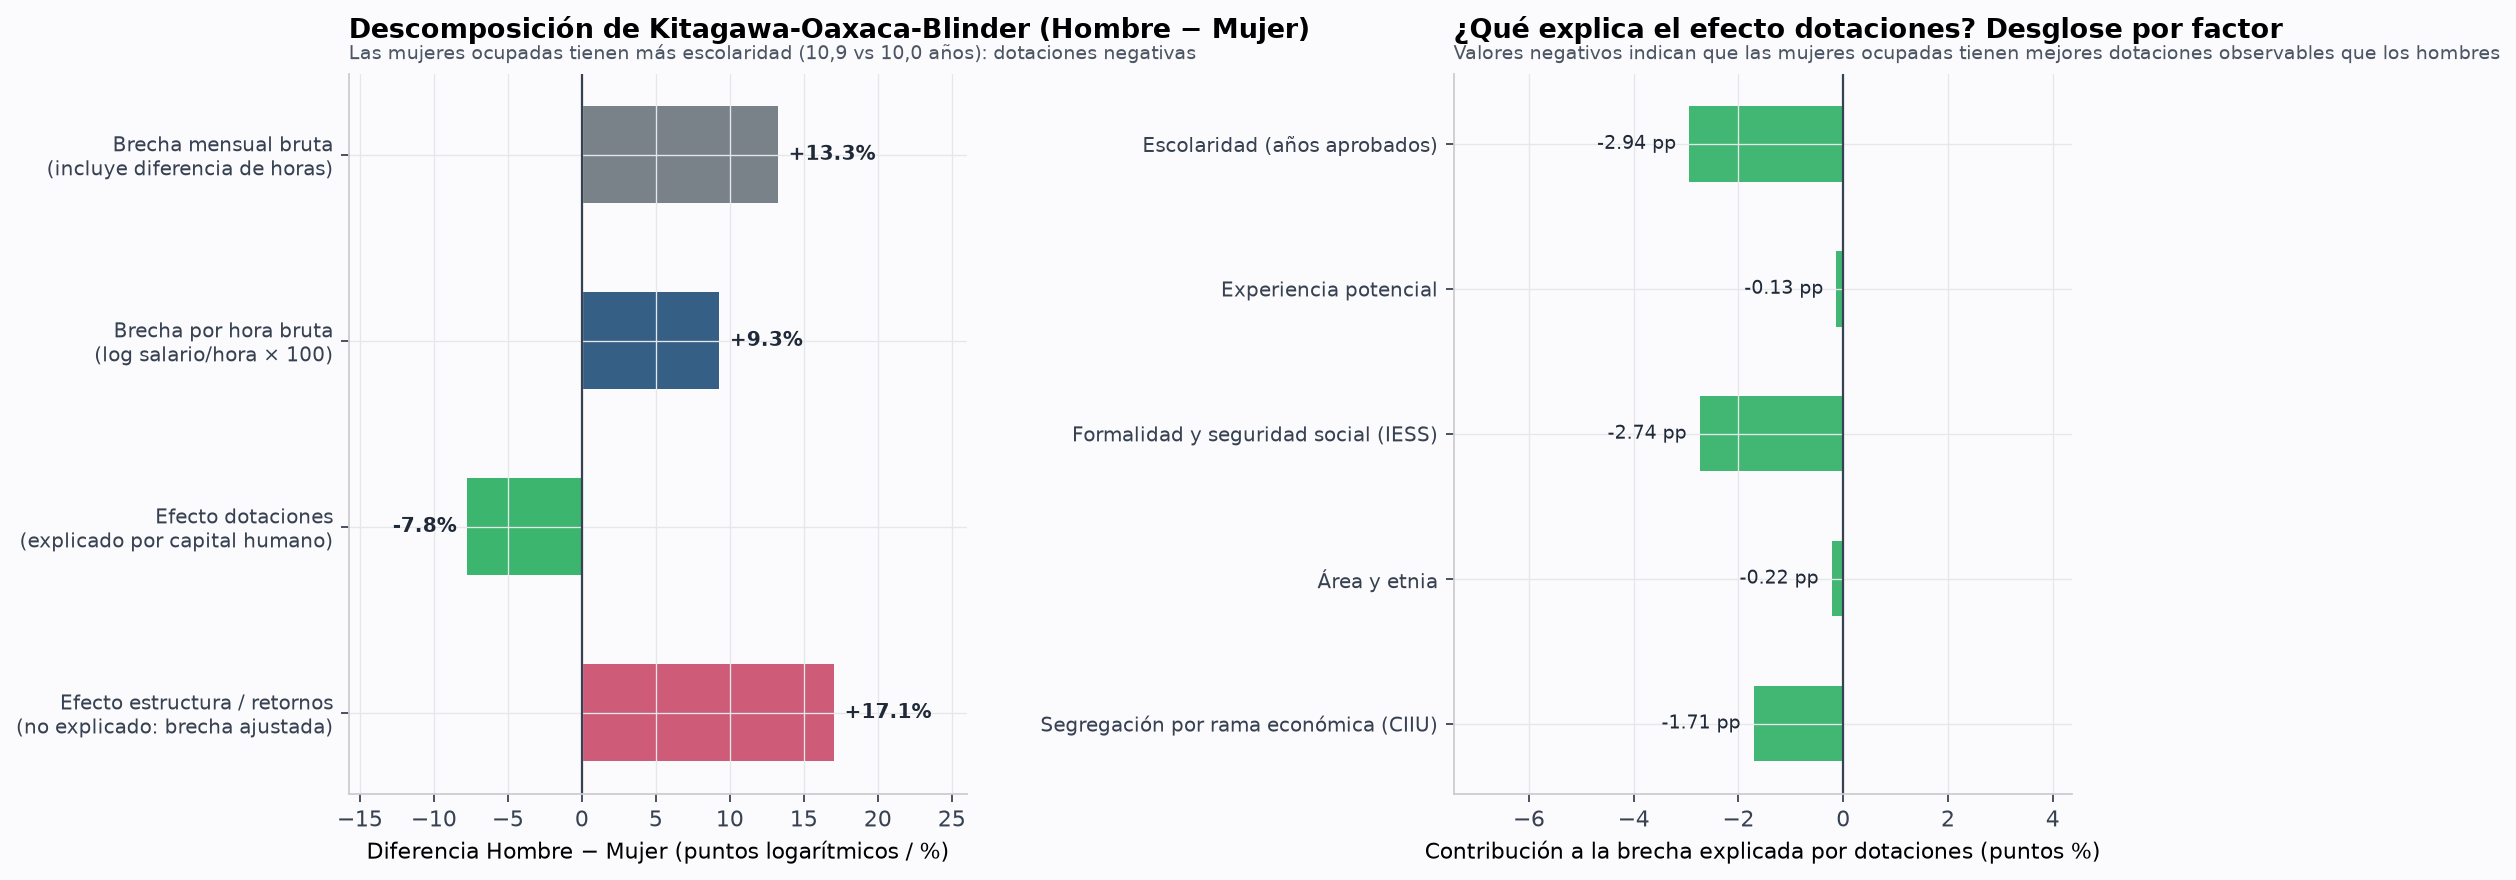

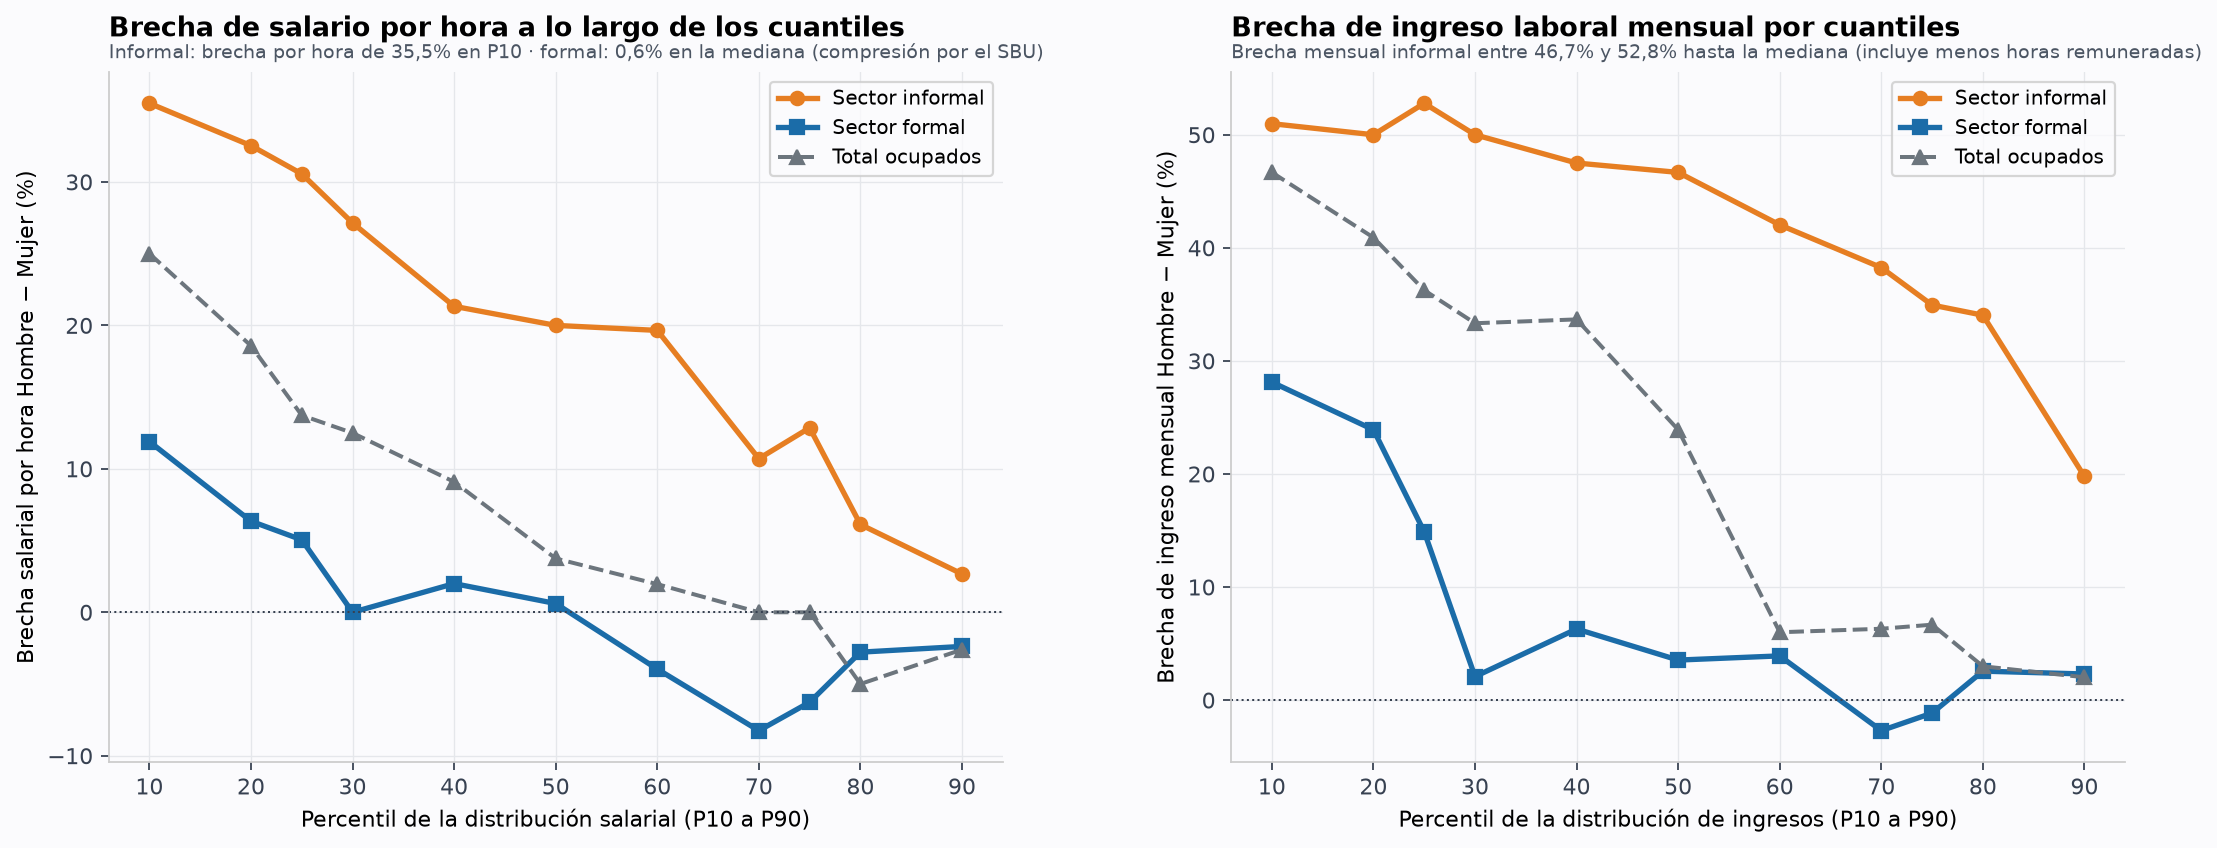

In [5]:
import tempfile
from pathlib import Path
from IPython.display import Image, display
from empleo_enemdu import graficos

# Las figuras se regeneran aquí desde los datos (en una carpeta temporal) y se muestran en línea
DIR_TMP = Path(tempfile.mkdtemp())

display(Image(filename=graficos.fig_08_oaxaca_blinder_brecha_genero(oax, DIR_TMP)))
display(Image(filename=graficos.fig_09_brecha_cuantilica_piso_pegajoso_techo_cristal(df_q, DIR_TMP)))